[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BASE-Laboratory/OpenImpala/blob/master/tutorials/02_microstructure_and_anisotropy.ipynb)

# Microstructural Metrics, Anisotropy, and Non-Cubic Voxels

Effective transport coefficients depend on three geometric features beyond bulk porosity: interfacial surface area per unit volume $S_V$, phase connectivity (percolating backbone versus isolated inclusions), and directional anisotropy arising either from material processing (e.g. electrode calendering or sedimentary bedding) or from non-cubic voxel spacing $(h_z, h_y, h_x)$ in serial-sectioning tomography.

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q openimpala matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import openimpala as oi

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## Cauchy–Crofton Specific Surface Area and Particle Sizing

Counting raw Cartesian voxel faces between two phases overestimates the area of smooth curved interfaces by a factor of $3/2$ in 3D (the ratio of the $\ell_1$ to $\ell_2$ sphere projection). OpenImpala's `specific_surface_area()` reports both the raw face-area density (`ssa`) and the isotropic Cauchy–Crofton stereological estimate (`ssa_corrected` $= \frac{2}{3} S_V^{\text{raw}}$).

We verify both estimators on `oi.datasets.sphere_pack()`, a $100^3$ volume ($h = 1.0\;\mu\mathrm{m}$) containing $N = 8$ non-overlapping solid spheres (`phase=0`) of radius $R = 15\;\mu\mathrm{m}$, where the exact interfacial area density is

$$S_V^{\text{exact}} = \frac{N \cdot 4\pi R^2}{L^3} = \frac{8 \times 4\pi (15)^2}{100^3} = 0.022619\;\mu\mathrm{m}^{-1}.$$

In [3]:
spheres = oi.datasets.sphere_pack()
ssa = oi.specific_surface_area(spheres, phase_a=0, phase_b=1, voxel_size=1.0)
sv_exact = 8.0 * 4.0 * np.pi * (15.0**2) / spheres.size

print(f"Analytical S_V:         {sv_exact:.5f} um^-1")
print(f"Raw voxel face S_V:     {ssa.ssa:.5f} um^-1  ({(ssa.ssa / sv_exact - 1)*100:+.1f}%)")
print(f"Cauchy-Crofton S_V:     {ssa.ssa_corrected:.5f} um^-1  ({(ssa.ssa_corrected / sv_exact - 1)*100:+.2f}%)")
ssa

Analytical S_V:         0.02262 um^-1
Raw voxel face S_V:     0.03346 um^-1  (+47.9%)
Cauchy-Crofton S_V:     0.02230 um^-1  (-1.39%)


Metric,Value
SSA (raw),3.345600e-02
SSA (2/3 Cauchy–Crofton),2.230400e-02
SSA (voxel⁻¹),0.033456
"Interfacial faces (x, y, z)","33,456 (11,152, 11,152, 11,152)"
Evaluated voxels,"1,000,000"


6-connected component labelling (`connected_components`) and equivalent-sphere sizing (`particle_size_distribution`) recover the individual particles and their radii $R_{\text{eq}} = (3V / 4\pi)^{1/3}$:

In [4]:
ccl_spheres = oi.connected_components(spheres, phase=0, return_labels=True)
psd = oi.particle_size_distribution(spheres, phase=0, voxel_size=1.0)
psd

Metric,Value
Particles,8
Mean radius,14.9503
R10 / R50 / R90,14.95 / 14.95 / 14.95


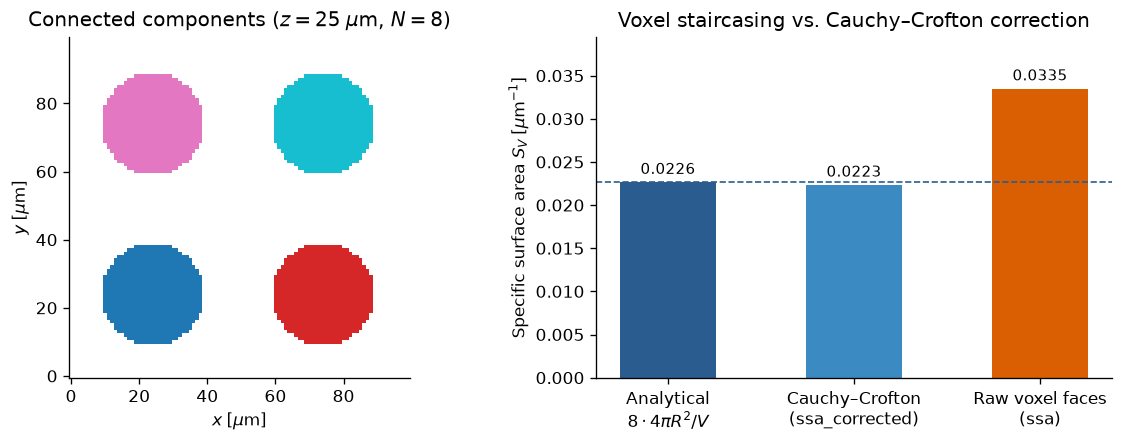

In [5]:
z_cut = 25  # plane intersecting four sphere centres
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), constrained_layout=True)

masked_labels = np.ma.masked_where(ccl_spheres.labels[z_cut] == 0, ccl_spheres.labels[z_cut])
axes[0].imshow(spheres[z_cut], origin="lower", cmap="Greys_r", alpha=0.25)
axes[0].imshow(masked_labels, origin="lower", cmap="tab10", interpolation="nearest")
axes[0].set_title(rf"Connected components ($z = {z_cut}\;\mu$m, $N = {psd.num_particles}$)")
axes[0].set_xlabel(r"$x\;[\mu\mathrm{m}]$")
axes[0].set_ylabel(r"$y\;[\mu\mathrm{m}]$")

methods = [
    "Analytical\n" + r"$8 \cdot 4\pi R^2 / V$",
    "Cauchy–Crofton\n(ssa_corrected)",
    "Raw voxel faces\n(ssa)",
]
values = [sv_exact, ssa.ssa_corrected, ssa.ssa]
colors = ["#2b5c8f", "#3b8bc2", "#d95f02"]
bars = axes[1].bar(methods, values, color=colors, width=0.52)
axes[1].axhline(sv_exact, color="#2b5c8f", ls="--", lw=1.0)
axes[1].set_ylabel(r"Specific surface area $S_V\;[\mu\mathrm{m}^{-1}]$")
axes[1].set_title("Voxel staircasing vs. Cauchy–Crofton correction")
axes[1].bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
axes[1].set_ylim(0, max(values) * 1.18)

plt.show()

## Percolating Backbone and Through-Thickness Porosity Profiles

In heterogeneous porous media, part of the void space can be trapped in disconnected cavities that contribute to bulk porosity $\varepsilon$ without carrying steady-state flux. Combining `connected_components()` with `through_thickness_profile()` separates dead-end volume from slice-to-slice porosity variations.

In [6]:
cubic = oi.datasets.two_phase_cubic()
h_um = 0.5

pore_ccl = oi.connected_components(cubic, phase=1)
largest_share = pore_ccl.volumes.max() / pore_ccl.volumes.sum()
print(
    f"Pore components: {pore_ccl.num_components} "
    f"(largest spanning network holds {largest_share:.2%} of pore volume)"
)

prof_z = oi.through_thickness_profile(cubic, phase=1, direction="z", voxel_size=h_um)
prof_z

Pore components: 120 (largest spanning network holds 99.43% of pore volume)


Metric,Value
Direction,z
Slices,64
Profile (min / mean / max),0.3450 / 0.3993 / 0.4399


## Directional Tortuosity and Non-Cubic FIB-SEM Voxels

`oi.tortuosity_all()` evaluates steady-state transport across $(x, y, z)$ in a single call, returning `None` for any non-percolating axis when `strict=False` (the default).

Tomographic instruments such as focused-ion-beam SEM (FIB-SEM) frequently acquire images with coarser slice milling spacing $h_z$ than in-plane pixel pitch $(h_x, h_y)$. Passing a 3-tuple `voxel_size=(dz, dy, dx)` scales the finite-volume face conductances $A_d / h_d$ properly: doubling $h_z$ from $0.5\;\mu\mathrm{m}$ to $1.0\;\mu\mathrm{m}$ elongates the sample along $z$, reducing relative lateral detour cost for $z$-transport ($\tau_z$ drops) while penalising $z$-plane detours during $x$- and $y$-transport ($\tau_x, \tau_y$ increase).

In [7]:
tau_iso = oi.tortuosity_all(cubic, phase=1, voxel_size=(0.5, 0.5, 0.5))
tau_fib = oi.tortuosity_all(cubic, phase=1, voxel_size=(1.0, 0.5, 0.5))

for d in ("x", "y", "z"):
    print(
        f"Direction {d.upper()}:  tau_iso = {tau_iso[d].tortuosity:.4f},  "
        f"tau_aniso(dz=2*dx) = {tau_fib[d].tortuosity:.4f}"
    )

Direction X:  tau_iso = 3.3103,  tau_aniso(dz=2*dx) = 4.4490
Direction Y:  tau_iso = 3.3684,  tau_aniso(dz=2*dx) = 4.5367
Direction Z:  tau_iso = 3.3977,  tau_aniso(dz=2*dx) = 2.2957


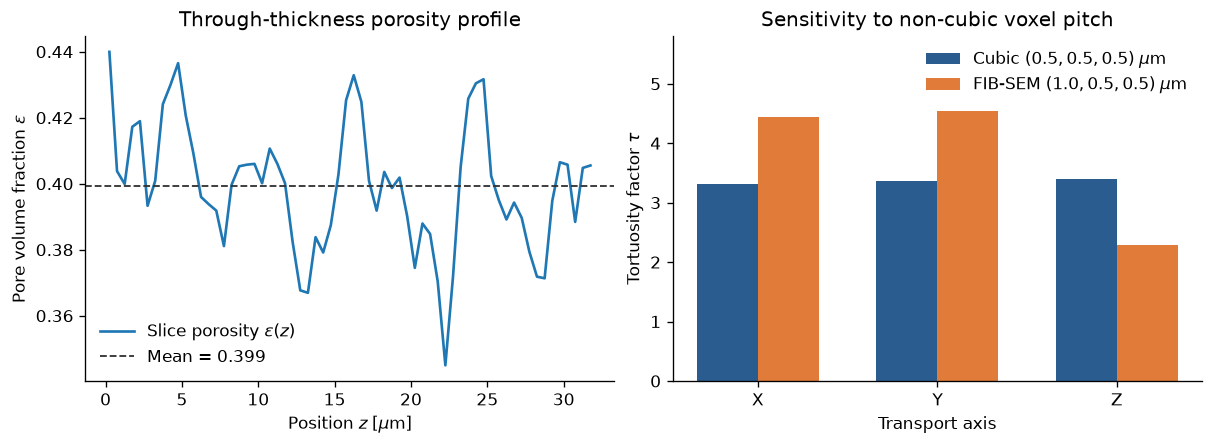

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.6), constrained_layout=True)

mean_eps = float(prof_z.profile.mean())
axes[0].plot(prof_z.positions, prof_z.profile, color="#1f77b4", lw=1.6, label=r"Slice porosity $\varepsilon(z)$")
axes[0].axhline(mean_eps, color="#333333", ls="--", lw=1.1, label=f"Mean = {mean_eps:.3f}")
axes[0].set_xlabel(r"Position $z\;[\mu\mathrm{m}]$")
axes[0].set_ylabel(r"Pore volume fraction $\varepsilon$")
axes[0].set_title("Through-thickness porosity profile")
axes[0].legend(frameon=False)

dirs = ["x", "y", "z"]
xpos = np.arange(len(dirs))
w = 0.34
axes[1].bar(
    xpos - w / 2,
    [tau_iso[d].tortuosity for d in dirs],
    width=w,
    color="#2b5c8f",
    label=r"Cubic $(0.5, 0.5, 0.5)\;\mu$m",
)
axes[1].bar(
    xpos + w / 2,
    [tau_fib[d].tortuosity for d in dirs],
    width=w,
    color="#e07b39",
    label=r"FIB-SEM $(1.0, 0.5, 0.5)\;\mu$m",
)
axes[1].set_xticks(xpos, [d.upper() for d in dirs])
axes[1].set_xlabel("Transport axis")
axes[1].set_ylabel(r"Tortuosity factor $\tau$")
axes[1].set_title("Sensitivity to non-cubic voxel pitch")
axes[1].set_ylim(0, 5.8)
axes[1].legend(frameon=False, loc="upper right")

plt.show()

## References

1. J. Ohser and F. Mücklich, *Statistical Analysis of Microstructures in Materials Science*, Wiley (2000).